# Proyecto OLIST — Análisis y modelado del riesgo de entrega tardía
**Universidad Latina de Costa Rica · Minería de Datos · Proyecto 1**

**Objetivo:** identificar, al confirmar una orden, los pedidos con mayor riesgo de llegar después de la fecha estimada.

Este notebook complementa los scripts existentes del equipo. **No sustituye ni modifica** `bronze_carga_completa.py`, `silver.py`, `gold.py` ni `modelo_clasificacion.py`. Requiere ejecutarse dentro de la carpeta `ProyectoRiesgoTardio` y disponer de SQL Server para regenerar todo el pipeline.

**Control temporal:** el modelo vigente usa seis predictores y particiona por `order_approved_at`; consulte las secciones 3 y 7 para supuestos y limitaciones.


## 1. Preparación y comprobación de archivos
Se comprueba que los scripts y archivos de resultados estén en la carpeta del proyecto. Si el CSV Gold no existe, ejecutar primero el pipeline según el README.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

PROYECTO = Path.cwd()
if not (PROYECTO / "modelo_clasificacion.py").exists():
    raise FileNotFoundError("Abre este notebook desde la carpeta ProyectoRiesgoTardio.")
for nombre in ["bronze_carga_completa.py", "silver.py", "gold.py", "modelo_clasificacion.py"]:
    print(nombre, "OK" if (PROYECTO / nombre).exists() else "NO ENCONTRADO")


bronze_carga_completa.py OK
silver.py OK
gold.py OK
modelo_clasificacion.py OK


## 2. Carga y exploración de Gold
La tabla `order_delivery_risk_features` tiene **una fila por `order_id`**. `late_delivery` es 1 cuando la entrega real superó la fecha estimada, y 0 en caso contrario. Los pedidos sin fechas comparables no pueden etiquetarse para este entrenamiento.

In [2]:
ruta_gold = PROYECTO / "outputs" / "gold_order_delivery_risk_features.csv"
if not ruta_gold.exists():
    raise FileNotFoundError("Falta el CSV Gold. Ejecuta primero python gold.py en el proyecto.")
gold = pd.read_csv(ruta_gold, low_memory=False)
print("Dimensiones:", gold.shape)
print("Pedidos duplicados:", gold["order_id"].duplicated().sum())
display(gold.head())
display(gold.isna().sum().rename("valores_faltantes").to_frame())
assert gold["order_id"].is_unique, "Gold debe tener una fila por pedido"


Dimensiones: (96476, 18)
Pedidos duplicados: 0


,order_id,order_purchase_timestamp,order_approved_at,cantidad_items,cantidad_vendedores,valor_total,freight_value,peso_total_g,volumen_total_cm3,categoria_principal,estado_origen,estado_destino,distancia_km,mismo_estado,dia_semana_compra,mes_compra,dias_estimados_entrega,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,1.0,1.0,29.99,8.72,500.0,1976.0,utilidades_domesticas,SP,SP,18.576110,1,0,10,15.544063,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07-26 03:24:27,1.0,1.0,118.70,22.76,400.0,4693.0,perfumaria,SP,BA,851.495069,0,1,7,19.137766,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-08 08:55:23,1.0,1.0,159.90,19.22,420.0,9576.0,automotivo,SP,GO,514.410666,0,2,8,26.639711,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-11-18 19:45:59,1.0,1.0,45.00,27.20,450.0,6000.0,pet_shop,MG,RN,1822.226336,0,5,11,26.188819,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-13 22:20:29,1.0,1.0,19.90,8.72,250.0,11475.0,papelaria,SP,SP,29.676625,1,1,2,12.112049,0


,valores_faltantes
order_id,0
order_purchase_timestamp,0
order_approved_at,14
cantidad_items,0
cantidad_vendedores,0
valor_total,0
freight_value,0
peso_total_g,16
volumen_total_cm3,16
categoria_principal,1358


,pedidos,porcentaje
late_delivery,,
0,88649,91.89
1,7827,8.11


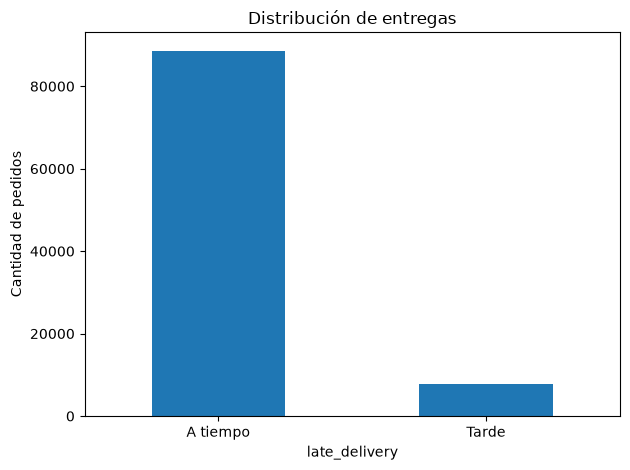

In [3]:
distribucion = gold["late_delivery"].value_counts().sort_index()
display(pd.DataFrame({"pedidos": distribucion, "porcentaje": (distribucion / len(gold) * 100).round(2)}))
ax = distribucion.rename(index={0:"A tiempo",1:"Tarde"}).plot.bar(title="Distribución de entregas", rot=0)
ax.set_ylabel("Cantidad de pedidos")
plt.tight_layout()
plt.show()


## 3. Variables predictoras y prevención de fuga temporal
El modelo usa variables de la orden, sus ítems, vendedor, cliente y ubicación. **No debe usar como predictor** `order_delivered_customer_date`, `late_delivery` ni otros datos conocidos después de la entrega. La fecha real de entrega se usa únicamente para construir la etiqueta histórica.

**Validación pendiente de negocio:** documentar que la fecha estimada, el precio, el envío y los atributos del pedido estaban disponibles en el momento exacto de confirmación. Los resultados se basan en pedidos históricos con etiqueta observable, no en pedidos activos.

In [4]:
variables_modelo = [
    "cantidad_items",
    "valor_total",
    "freight_value",
    "dia_semana_compra",
    "mes_compra",
    "dias_estimados_entrega",
]
print("Predictores autorizados:")
for columna in variables_modelo:
    print("-", columna)
print("Referencia temporal excluida del modelo: order_approved_at")
print("Variable objetivo:", "late_delivery")


Predictores autorizados:
- cantidad_items
- valor_total
- freight_value
- dia_semana_compra
- mes_compra
- dias_estimados_entrega
Referencia temporal excluida del modelo: order_approved_at
Variable objetivo: late_delivery


### Validacion de variables predictoras y prevencion de fuga temporal

El momento de prediccion se aproxima con la aprobacion de la orden (`order_approved_at`). Esta fecha se usa solo para ordenar y dividir los datos; no entra al clasificador. La fecha real de entrega solo construye `late_delivery` y nunca es predictor.

El modelo usa una lista explicita de seis predictores: cantidad de items, valor total, flete, dia y mes de compra y dias estimados de entrega. Se excluyeron vendedor, cliente, catalogo y geolocalizacion porque OLIST no conserva sus fechas de asignacion, vigencia o actualizacion; la geolocalizacion, ademas, se agrega sobre todo el periodo.

Se asume que el contenido, el precio, el flete y la fecha estimada ya se conocen al aprobar la orden. OLIST no incluye marcas de tiempo por campo, por lo que esa disponibilidad no puede demostrarse por completo y debe reportarse como limitacion.


## 4. Entrenamiento y comparacion de modelos
El archivo `modelo_clasificacion.py` usa una lista explicita de predictores, divide cronologicamente por `order_approved_at`, ajusta el preprocesamiento dentro de cada pipeline y compara DummyClassifier, regresion logistica, Random Forest e HistGradientBoosting. La seleccion se hace por PR-AUC de validacion y el umbral por F1 de validacion.

Para volver a entrenar, primero genere Gold y luego ejecute `modelo_clasificacion.py`. El script lee el CSV Gold y no importa ni reconstruye Gold al entrenar.


In [5]:
comparacion = pd.DataFrame({
    "Modelo": [
        "DummyClassifier (baseline)",
        "Regresion Logistica",
        "Random Forest",
        "HistGradientBoosting"
    ],
    "PR-AUC validacion": [
        0.0810,
        0.1165,
        0.1167,
        0.1289
    ]
})

display(comparacion.sort_values(
    "PR-AUC validacion", ascending=False
))


,Modelo,PR-AUC validacion
3,HistGradientBoosting,0.1289
2,Random Forest,0.1167
1,Regresion Logistica,0.1165
0,DummyClassifier (baseline),0.0810


In [6]:
# EJECUCION OPCIONAL DEL MODELO (Gold debe haberse generado antes):
# import subprocess, sys
# resultado = subprocess.run([sys.executable, "modelo_clasificacion.py"],
#                            cwd=PROYECTO, capture_output=True, text=True, check=True)
# (PROYECTO / "resultados_modelo.txt").write_text(resultado.stdout, encoding="utf-8")
# print(resultado.stdout[-12000:])
print("Ejecute primero gold.py y luego modelo_clasificacion.py para actualizar los resultados.")


Ejecute primero gold.py y luego modelo_clasificacion.py para actualizar los resultados.


## 5. Evaluación y métricas
Se muestran los resultados históricos que generó el script del equipo, si existe `resultados_modelo.txt`. Los valores **no se recalculan aquí** sin volver a ejecutar el modelo. La matriz de confusión corresponde al conjunto temporal de prueba.

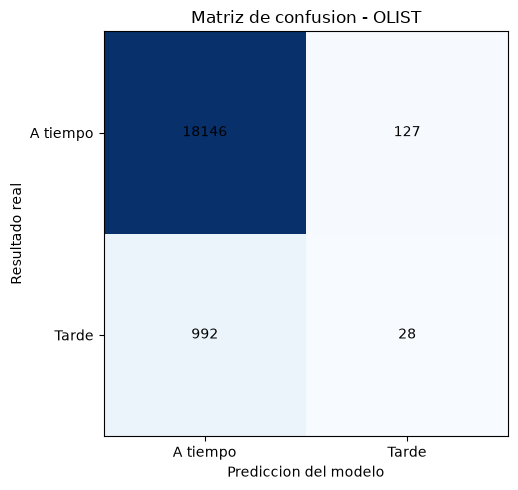

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Matriz del modelo conservador, umbral 0.15, conjunto temporal de prueba.
matriz = np.array([
    [18146, 127],
    [992, 28]
])

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(matriz, cmap="Blues")
ax.set_xticks([0, 1], ["A tiempo", "Tarde"])
ax.set_yticks([0, 1], ["A tiempo", "Tarde"])
ax.set_xlabel("Prediccion del modelo")
ax.set_ylabel("Resultado real")
ax.set_title("Matriz de confusion - OLIST")

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(matriz[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()


## 6. Ranking de riesgo y propuesta de negocio
El ranking corresponde a **pedidos históricos del conjunto de prueba**; no representa órdenes activas. La revisión humana es una **recomendación operativa**, no una intervención que el equipo ya haya realizado.

In [8]:
ruta_ranking = PROYECTO / "outputs" / "pedidos_priorizados.csv"
if ruta_ranking.exists():
    ranking = pd.read_csv(ruta_ranking)
    print("Pedidos en ranking:", len(ranking))
    print("Columnas:", ranking.columns.tolist())
    display(ranking.head(10))
else:
    print("No se encontró el ranking. Ejecutar modelo_clasificacion.py para generarlo.")


Pedidos en ranking: 19293
Columnas: ['prioridad', 'order_id', 'order_purchase_timestamp', 'probabilidad_retraso', 'umbral_seleccionado', 'priorizar']


,prioridad,order_id,order_purchase_timestamp,probabilidad_retraso,umbral_seleccionado,priorizar
0,1,ea110ced6459b4dc6c73e0b2367077e9,2018-06-17 20:32:45,0.481773,0.15,True
1,2,11658ef3bdfaf6a5d20927c19404c1d7,2018-06-25 16:50:08,0.434448,0.15,True
2,3,0fc95c806aba2b8aef43db06838ec606,2018-08-23 21:49:33,0.429337,0.15,True
3,4,ab4354630db26a599455989a1091e50f,2018-07-24 23:09:26,0.394869,0.15,True
4,5,fbc8e8d5591dc594ede3b88033625bd0,2018-08-16 23:24:34,0.381327,0.15,True
5,6,1adbc05f8bb9f7f40e1566992a9b5e8d,2018-08-19 09:35:34,0.371757,0.15,True
6,7,372f8e1a08cbd807194b89b3c31a448a,2018-08-25 15:12:30,0.367312,0.15,True
7,8,5d93a32a25ed8f8e884e5a1d283c43dd,2018-06-19 11:23:30,0.336960,0.15,True
8,9,95549a3370d5fe86da9749cae8d5aa45,2018-08-11 18:37:26,0.313227,0.15,True
9,10,a91e629d7c60ee83c467d41250528cc5,2018-08-12 17:34:48,0.290619,0.15,True


## 7. Interpretacion y limitaciones
- El modelo elegido fue **HistGradientBoosting**, seleccionado por PR-AUC de validacion (0.1289).
- El umbral 0.15 se eligio maximizando F1 en validacion.
- En prueba temporal obtuvo **Precision 18.06 %**, **Recall 2.75 %**, **F1 0.0477**, **ROC-AUC 0.7500** y **PR-AUC 0.1251**.
- Detecto 28 de 1,020 atrasos y genero 155 alertas. El bajo Recall no permite recomendarlo para una operacion real con este umbral.
- La fecha de aprobacion define las particiones, pero no es predictor. Se excluyeron variables historicas sin marcas temporales disponibles.
- Se asume que los items, precios, flete y fecha estimada se conocen al aprobar la orden; OLIST no contiene marcas de tiempo por campo para comprobarlo.
- Solo se incluyen pedidos historicos con etiqueta observable y aprobacion registrada; el modelo no puntua pedidos activos.

**Conclusion:** el proyecto implementa un pipeline analitico y una evaluacion temporal conservadora. La disponibilidad historica de algunos campos sigue siendo una limitacion y el modelo no demuestra reduccion de atrasos en produccion.


### Principales factores asociados a la prediccion del riesgo de entrega tardia

La importancia por permutacion se calculo sobre 5.000 pedidos del conjunto de prueba, con PR-AUC como metrica. Los factores con mayor caida media de PR-AUC fueron:

1. **Dias estimados de entrega:** 0.07636.
2. **Costo del envio:** 0.01697.
3. **Valor total:** 0.01603.
4. **Cantidad de articulos:** 0.00814.
5. **Dia de semana de compra:** 0.00311.

La importancia negativa de `mes_compra` (-0.00522) indica que su permutacion no redujo el PR-AUC en esta evaluacion. Estos valores describen aporte predictivo, no causalidad.


### Seleccion y justificacion del umbral

HistGradientBoosting obtuvo el mejor PR-AUC en validacion (0.1289). El umbral 0.15 se eligio maximizando F1 en validacion, sin consultar el conjunto de prueba.

En prueba, el umbral genero 155 alertas: 28 verdaderos positivos y 127 falsos positivos; dejo 992 atrasos sin detectar. Precision fue 18.06 %, Recall 2.75 % y F1 0.0477.

Como referencia, el umbral 0.05 detecto 825 atrasos (Recall 80.88 %) pero genero 8.744 alertas. La diferencia evidencia el compromiso entre capacidad de deteccion y carga de revision; el umbral no debe considerarse operativo sin conocer la capacidad y costos del negocio.


## 8. Entregables relacionados
- `outputs/gold_order_delivery_risk_features.csv`: dataset analítico.
- `resultados_modelo.txt`: métricas y comparación de modelos.
- `outputs/pedidos_priorizados.csv`: lista histórica priorizada.
- `outputs/reporte_riesgo_entrega.html`: visualización y propuesta preventiva.
- `README.md`: pasos para ejecutar el proyecto.
- `modelo_clasificacion.py`: implementación reproducible del entrenamiento.

